# 🎓 第3章 第1课：数据处理与七大因子构造

**本节目标**：从原始日线出发，走完因子研究的第一步——把数据变成可比较的月度面板，再构造七大因子。

对应原书 3.1 节（数据处理）与 3.2~3.8 节（七大因子）。

> ⚠️ 数据说明：日线行情是真实 A 股快照；估值只有一期快照，ROE/投资等逐期面板是**教学用合成面板**。
> 本 notebook 演示方法与流程，数值不代表真实 A 股的历史实证结论。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.statistics import factor_summary, nw_t_stat
from factor_zero.sorting import long_short_factor, monotonicity_test

FACTOR_NAMES = ['MKT', 'SMB', 'HML', 'WML', 'RMW', 'CMA', 'TURN']
FACTOR_CN = {'MKT': '市场', 'SMB': '规模', 'HML': '价值',
             'WML': '动量', 'RMW': '盈利', 'CMA': '投资', 'TURN': '换手率'}

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 1) 数据处理：从日线到月度面板

因子研究的第一步不是“算因子”，而是**把数据处理干净**。原书 3.1 节的流程：

1. 月度调仓，用月末收盘价算月收益；
2. 剔除 ST/*ST、退市、负净资产、次新股；
3. 缩尾（1%/99%）处理极端值；
4. 剔除一字涨跌停；
5. 保留金融股（银行/券商/保险），不做行业剔除。

本仓库的示例数据只有 87 只股票的快照，无法完整执行 2~4 步；notebook 保留**完整历史**的 81 只股票，
并在因子层面做极端值裁剪。真实研究请按原书流程补齐。

In [2]:
panel = load_ashare_panel()
print('股票数:', panel['ret'].shape[1])
print('月份数:', panel['ret'].shape[0])
print('时间范围:', panel['ret'].index.min().date(), '→', panel['ret'].index.max().date())
panel['ret'].head(3).round(4)

股票数: 81
月份数: 83
时间范围: 2018-02-28 → 2024-12-31


,000001,000002,000063,000100,000333,000338,000568,000625,000651,000725,...,601636,601668,601688,601728,601857,601888,601899,601989,601995,603501
date,,,,,,,,,,,,,,,,,,,,,
2018-02-28,-0.1423,-0.1293,0.0359,0.0478,-0.0813,-0.0319,-0.1056,-0.0649,-0.0758,-0.0701,...,-0.1293,-0.0996,-0.1173,0.0360,-0.1116,0.0211,-0.1017,-0.0794,0.2066,0.0433
2018-03-31,-0.0954,0.0182,-0.0650,-0.0737,-0.0075,-0.0282,-0.0285,-0.0641,-0.0927,-0.0591,...,-0.1419,-0.0497,-0.0029,0.0813,-0.0449,0.0104,-0.0553,-0.0528,-0.0434,0.2111
2018-04-30,-0.0048,-0.1471,0.0386,-0.0644,-0.0523,0.0000,0.0615,-0.0779,-0.0601,-0.1883,...,-0.0840,-0.0309,0.0630,0.0040,0.0000,-0.0159,-0.0529,-0.0613,0.0504,-0.0857


## 2) 七大因子：定义与方向

| 代码 | 因子 | 构造 | 方向（多空组合） |
|---|---|---|---|
| MKT | 市场 | 市值加权市场收益 | 示意，未减无风险利率 |
| SMB | 规模 | 对数市值排序 | 小市值 − 大市值 |
| HML | 价值 | BM = 1/PB 排序 | 高 BM − 低 BM |
| WML | 动量 | 12-1 月累计收益排序 | 高动量 − 低动量 |
| RMW | 盈利 | ROE 排序 | 高 ROE − 低 ROE |
| CMA | 投资 | 投资强度排序 | 低投资 − 高投资 |
| TURN | 换手率 | 月换手率排序 | 低换手 − 高换手 |

> 方向很重要：同一个变量，做多高组还是低组，得到的因子收益符号完全不同。
> 这里按“经济逻辑上预期为正”的方向定义；实际显著性和符号要由数据检验。

In [3]:
factors = build_factor_returns(panel, n_groups=10)
factors.head(3).round(4)

,MKT,SMB,HML,WML,RMW,CMA,TURN
date,,,,,,,
2018-03-31,-0.0403,0.1530,-0.0611,NaN,0.0349,-0.0067,-0.0328
2018-04-30,-0.0307,0.0492,0.0583,NaN,-0.0712,0.0005,-0.0045
2018-05-31,0.0159,-0.0143,-0.0495,NaN,0.0528,0.0483,0.0270


### 因子绩效速览

用第2章的 NW t 检验，先看每个因子的年化收益、波动、Sharpe 和显著性。

In [4]:
rows = {}
for col in factors.columns:
    s = factor_summary(factors[col].dropna())
    if s:
        rows[col] = s
summary = pd.DataFrame(rows).T
summary.index = [f'{k}（{FACTOR_CN.get(k, k)}）' for k in summary.index]
summary.columns = ['年化收益', '年化波动', 'Sharpe', 'NW t', '最大回撤', '胜率']
summary.round(4)

,年化收益,年化波动,Sharpe,NW t,最大回撤,胜率
MKT（市场）,0.0986,0.1744,0.5654,1.6306,-0.2577,0.5244
SMB（规模）,0.2510,0.2664,0.9421,2.0356,-0.4500,0.5976
HML（价值）,-0.2082,0.2830,-0.7356,-2.1130,-0.8511,0.3902
WML（动量）,0.1957,0.3543,0.5524,1.4069,-0.3914,0.6286
RMW（盈利）,0.1009,0.2316,0.4359,1.1690,-0.4335,0.5732
CMA（投资）,0.0297,0.1514,0.1963,0.4578,-0.4239,0.5488
TURN（换手率）,-0.0533,0.3153,-0.1689,-0.4272,-0.8281,0.4756


## 3) 看净值：七个因子的累计表现

把每个因子看成一条可交易的多空组合，画累计净值（1 元起）。
注意：示例面板是教学数据，曲线形状只用于演示。

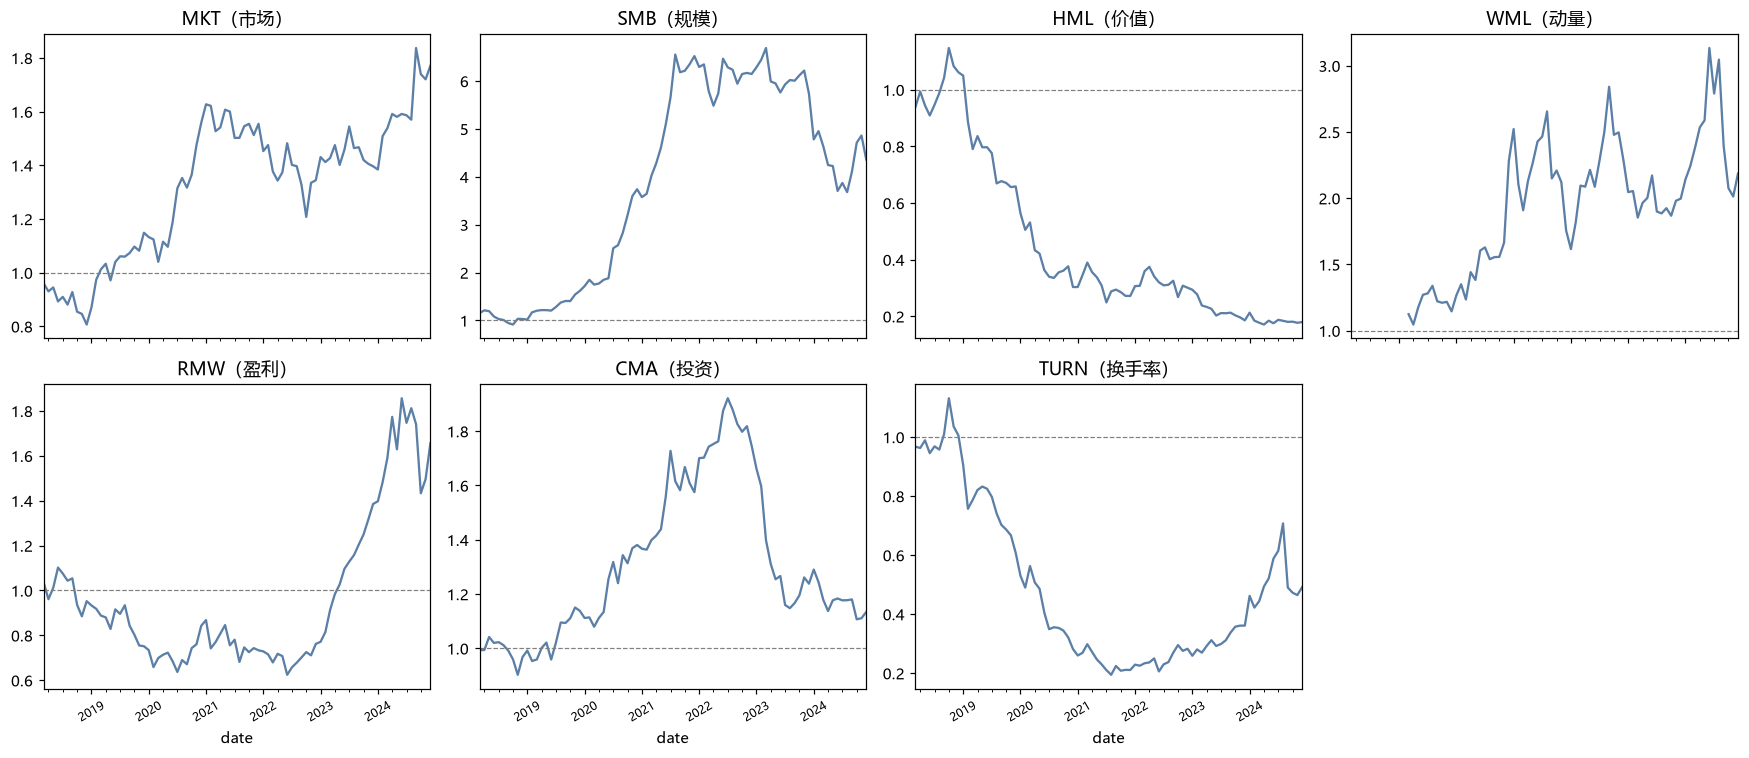

In [5]:
nav = (1 + factors).cumprod()
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, col in zip(axes.flat, FACTOR_NAMES):
    nav[col].dropna().plot(ax=ax, color='#5B7FA6')
    ax.set_title(f'{col}（{FACTOR_CN[col]}）')
    ax.axhline(1, color='gray', lw=.8, ls='--')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
for ax in axes.flat[len(FACTOR_NAMES):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 4) 因子相关性：它们是不是在说同一件事？

如果两个因子高度相关，它们可能只是同一个风险的两种叫法。
相关性矩阵是判断“因子冗余”的第一眼。

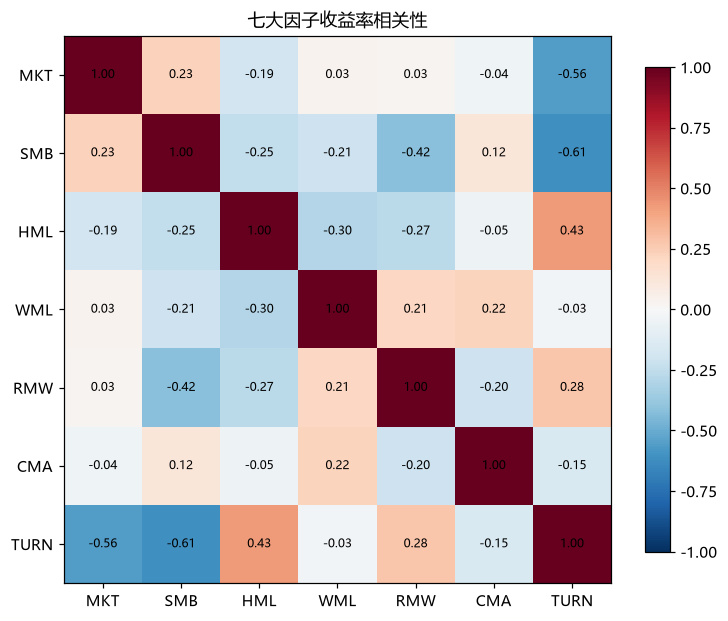

In [6]:
corr = factors.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax, shrink=.8)
ax.set_title('七大因子收益率相关性')
plt.tight_layout(); plt.show()

## ✋ 试一试

1. 把 `build_factor_returns` 的 `n_groups` 从 10 改成 5，因子收益和相关性会怎么变？
2. 把 `TURN` 的方向反过来（高换手 − 低换手），均值和 t 值符号怎么变？
3. 把 `MKT` 换成等权市场收益，和市值加权差多少？

## ✅ 本节小结

- 因子研究先做数据：月度化、对齐、剔除异常、缩尾；
- 七大因子都可以用“排序 → 分组 → 多空”统一构造；
- 方向是定义的一部分：做多高组还是低组，符号完全不同；
- 相关性矩阵是判断因子冗余的第一眼。

> 下一课：七个因子的分组单调性与多空组合细节。